# Exercise 5 - Boltzmann Solvers

In [49]:
from classy import Class
import camb
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
OUT = Path('output')
OUT.mkdir(exist_ok=True)

#Version for comparisons 
import classy
print('classy', classy.__version__)
print('camb', camb.__version__)
print('numpy', np.__version__)

classy v3.4.1
camb 2.0.4
numpy 2.5.3


### Reading the class_base.ini file

There is one massive neutrino in the file, with mass = 0.06 eV apparently. Not sure what 'N_ur' is (why isn't it an integer??). 

In [50]:
def read_ini(path):
    d = {}
    for line in open(path):
        line = line.split('#')[0].strip()
        if '=' in line:
            k, v = (s.strip() for s in line.split('=', 1))
            d[k] = v
    for k in ('format', 'headers', 'overwrite_root', 'root'):
        d.pop(k, None)
    return d

params = read_ini('CLASS_config/class_base.ini')
params #Returning the values in the notebook

{'output': 'tCl,pCl,lCl,mPk,dTk',
 'lensing': 'yes',
 'h': '0.674',
 'omega_b': '0.0224',
 'omega_cdm': '0.120',
 'Omega_k': '0',
 'N_ur': '2.0308',
 'N_ncdm': '1',
 'm_ncdm': '0.06',
 'T_ncdm': '0.71611',
 'tau_reio': '0.054',
 'A_s': '2.10e-9',
 'n_s': '0.965',
 'k_pivot': '0.05',
 'non linear': 'none',
 'P_k_max_h/Mpc': '5.0',
 'z_pk': '0',
 'l_max_scalars': '3000'}

### a) Running the given model and calculating P_rec in  CLASS

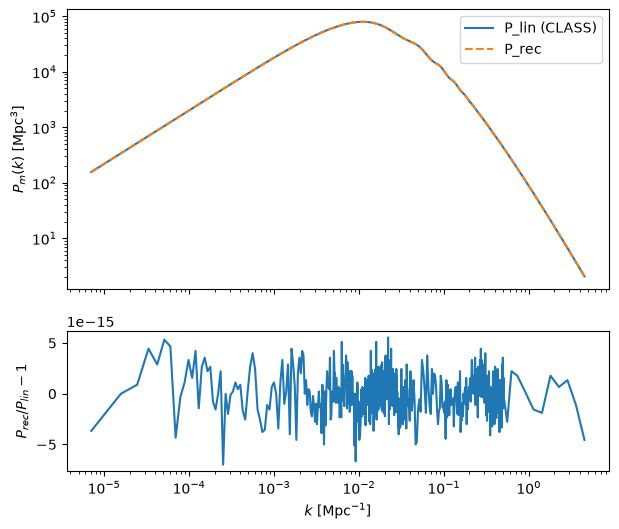

In [51]:
#Class Cosmology
cosmo = Class()
cosmo.set(params)
cosmo.compute()

h = cosmo.h()
t = cosmo.get_transfer(0)

# Parameters
k = h * t['k (h/Mpc)']
A_s = float(params['A_s'])
k_pivot = float(params['k_pivot'])
n_s = float(params['n_s'])

T_m = t['d_m'] #Apparently Class already normalizes the function by R

#Calculating P_rec
P_rec = (2*np.pi**2)/k**3 * A_s * (k/k_pivot)**(n_s-1) * T_m ** 2

#Comparison
P_lin = np.array([cosmo.pk_lin(k_num, 0) for k_num in k])
residual = P_rec/P_lin - 1

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6),
                               gridspec_kw={'height_ratios': [2, 1]})
ax1.loglog(k, P_lin, label='P_lin (CLASS)')
ax1.loglog(k, P_rec, '--', label='P_rec', )
ax1.set_ylabel(r'$P_m(k)\ [\mathrm{Mpc}^3]$'); ax1.legend()
ax2.semilogx(k, residual)
ax2.set_xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$'); ax2.set_ylabel(r'$P_{rec}/P_{lin}-1$')
fig.savefig(OUT / 'P_lin__P_rec.png', dpi=150)

Note that the fractional residual is of  maximum order $10^{-14}$ in this interval.

### b) (Still using CLASS)

**Explaining the reconstruction.** As stated before, the fractional residual is of order $10^{-14}$. Since both functions are derived from the same transfer function $T_m$, they may differ only by normalization (the constants and parameters) or by units (such as $k$). Therefore, even if $T_m$ was physically wrong, both functions would still be similar.

Now, let's compare the convergence of the spectrum, given different precision settings.

In [52]:
k_grid = np.logspace(-4, np.log10(3.0), 200) 

base_params = dict(params, output='mPk')
base_params.pop('lensing', None)
base_params.pop('l_max_scalars', None)

def pk_run(extra={}):
    c = Class()
    c.set(dict(base_params, **extra))
    c.compute()
    pk = np.array([c.pk_lin(kk, 0) for kk in k_grid])
    c.struct_cleanup()
    return pk

### Default and reference values with tighter precision settings:

**ODE tolerance:** tol_perturbations_integration

**Wave-number sampling:** k_per_decade_for_pk, k_per_decade_for_bao

**Time sampling:** perturbations_sampling_stepsize

**Hierarchy depth:** l_max_g, l_max_pol_g, l_max_ur, l_max_ncdm

**Approx. switch thresholds (??):** tight_coupling_trigger_tau_c_over_tau_h, radiation_streaming_trigger_tau_over_tau_k, ur_fluid_trigger_tau_over_tau_k, ncdm_fluid_trigger_tau_over_tau_k

**Massive-species momentum sampling:** tol_ncdm_synchronous

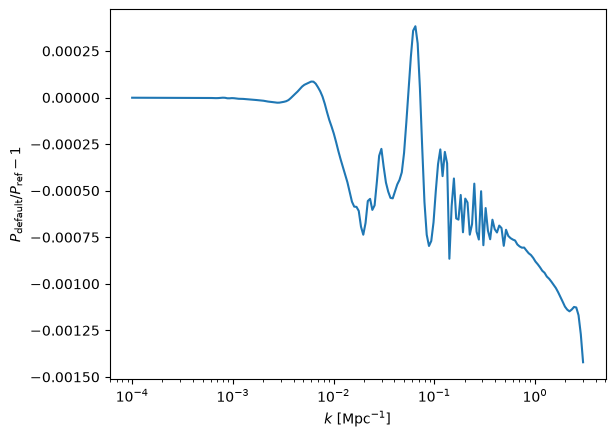

max |default/ref - 1| = 0.0014212041474606085


In [53]:
defaults = {
    'tol_perturbations_integration': 1e-5,
    'k_per_decade_for_pk': 10,
    'k_per_decade_for_bao': 70,
    'perturbations_sampling_stepsize': 0.1,
    'l_max_g': 12,
    'l_max_pol_g': 10,
    'l_max_ur': 17,
    'l_max_ncdm': 17,
    'tight_coupling_trigger_tau_c_over_tau_h': 0.015,
    'radiation_streaming_trigger_tau_over_tau_k': 45,
    'ur_fluid_trigger_tau_over_tau_k': 30,
    'ncdm_fluid_trigger_tau_over_tau_k': 31,
    'tol_ncdm_synchronous': 1e-3,
}

# The settings above correspond to the "Record the actual controls exposed by the chosen code".

ref_settings = {
    'tol_perturbations_integration': 1e-8,
    'k_per_decade_for_pk': 50,
    'k_per_decade_for_bao': 200,
    'perturbations_sampling_stepsize': 0.02,
    'l_max_g': 50, 'l_max_pol_g': 50, 'l_max_ur': 50, 'l_max_ncdm': 50,
    'tight_coupling_trigger_tau_c_over_tau_h': 0.003,
    'radiation_streaming_trigger_tau_over_tau_k': 240,
    'ur_fluid_trigger_tau_over_tau_k': 200,
    'ncdm_fluid_trigger_tau_over_tau_k': 220,
    'tol_ncdm_synchronous': 1e-6,
}
pk_ref  = pk_run(ref_settings)
pk_default = pk_run(defaults)

plt.semilogx(k_grid, pk_default/pk_ref - 1)
plt.xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$'); plt.ylabel(r'$P_\mathrm{default}/P_\mathrm{ref}-1$')
plt.savefig(OUT / 'b_default_vs_ref.png', dpi=150); plt.show()
print('max |default/ref - 1| =', np.abs(pk_default/pk_ref - 1).max())

### Plotting some of the fractional residual between different settings

tol_perturbations_integration                 1e-05  --- max|P/P_ref-1| = 1.42e-03
tol_perturbations_integration                 1e-06  --- max|P/P_ref-1| = 1.42e-03
tol_perturbations_integration                 1e-07  --- max|P/P_ref-1| = 1.42e-03
k_per_decade_for_pk                              10  --- max|P/P_ref-1| = 1.42e-03
k_per_decade_for_pk                              20  --- max|P/P_ref-1| = 1.25e-03
k_per_decade_for_pk                              50  --- max|P/P_ref-1| = 1.28e-03
perturbations_sampling_stepsize                 0.1  --- max|P/P_ref-1| = 1.42e-03
perturbations_sampling_stepsize                0.05  --- max|P/P_ref-1| = 1.42e-03
perturbations_sampling_stepsize                0.02  --- max|P/P_ref-1| = 1.42e-03
l_max_g                                          12  --- max|P/P_ref-1| = 1.42e-03
l_max_g                                          20  --- max|P/P_ref-1| = 1.42e-03
l_max_g                                          30  --- max|P/P_ref-1| = 1.42e-03
l_ma

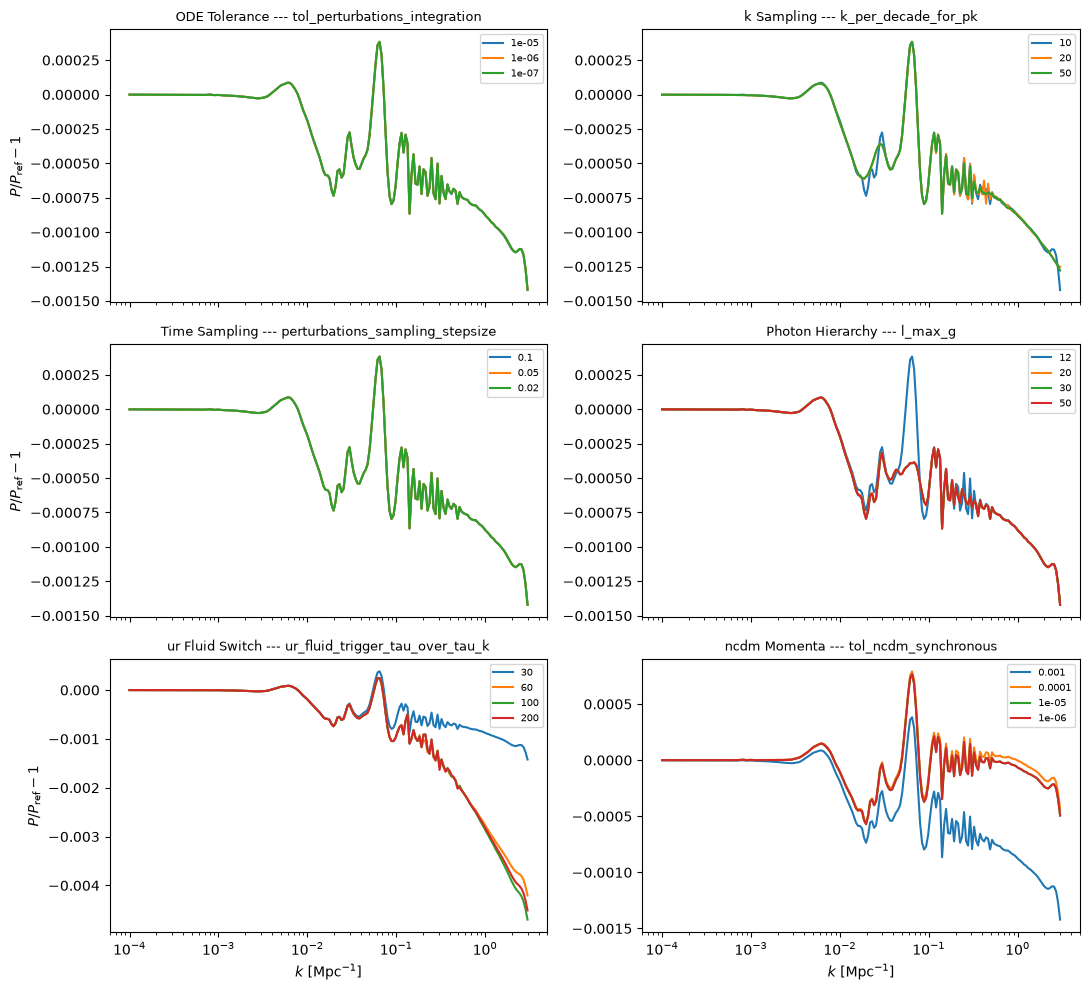

In [54]:
scans = {
    'ODE Tolerance':      ('tol_perturbations_integration', [1e-5, 1e-6, 1e-7]),
    'k Sampling':         ('k_per_decade_for_pk',           [10, 20, 50]),
    'Time Sampling':      ('perturbations_sampling_stepsize', [0.1, 0.05, 0.02]),
    'Photon Hierarchy':   ('l_max_g',                       [12, 20, 30, 50]),
    'ur Fluid Switch':    ('ur_fluid_trigger_tau_over_tau_k', [30, 60, 100, 200]),
    'ncdm Momenta':       ('tol_ncdm_synchronous',          [1e-3, 1e-4, 1e-5, 1e-6]),
}

fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
summary = {}
for ax, (title, (name, values)) in zip(axes.flat, scans.items()):
    for v in values:
        r = pk_run({name: v})/pk_ref - 1
        ax.semilogx(k_grid, r, label=f'{v}')
        summary[(name, v)] = np.abs(r).max()
    ax.set_title(f'{title} --- {name}', fontsize=9)
    ax.legend(fontsize=7)
for ax in axes[-1]: ax.set_xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$')
for ax in axes[:, 0]: ax.set_ylabel(r'$P/P_\mathrm{ref}-1$')
fig.tight_layout(); fig.savefig(OUT / 'b_scans.png', dpi=180)

for (setting, v), err in summary.items():
    print(f'{setting:40s} {v:>10}  --- max|P/P_ref-1| = {err:.2e}')

With default settings, CLASS reproduces the high-precision reference to $~0.1\%$ (max 1.4×10⁻³), dominated by the neutrino settings. 

### c) Comparing CLASS and CAMB

Should have the same physical properties. $N_{eff}$ and $Y_{He}$ are passed to CAMB from CLASS.

In [55]:
Neff = cosmo.Neff()
YHe = cosmo.get_current_derived_parameters(['YHe'])['YHe']

In [56]:
#CAMB parameters

def pk_camb(acc=1, nnu=Neff):
    pars = camb.set_params(
        H0=100*float(params['h']),
        ombh2=float(params['omega_b']), omch2=float(params['omega_cdm']), omk=0,
        mnu=float(params['m_ncdm']), num_massive_neutrinos=1, nnu=nnu, YHe=YHe,
        tau=float(params['tau_reio']),
        As=A_s, ns=n_s, pivot_scalar=k_pivot,
        WantTransfer=True, kmax=10, redshifts=[0.],
        NonLinear=camb.model.NonLinear_none,
        AccuracyBoost=acc, lAccuracyBoost=acc)
    res = camb.get_results(pars)
    PK = res.get_matter_power_interpolator(nonlinear=False, var1='delta_tot', var2='delta_tot',
                                           hubble_units=False, k_hunit=False)
    return PK.P(0, k_grid)

In [57]:
# Default settings in each code
pk_camb_default = pk_camb()
r_default = pk_camb_default/pk_default - 1

In [58]:
# Increasing precision settings
pk_camb_hi = pk_camb(acc=3)
r_hi = pk_camb_hi/pk_ref - 1

In [59]:
# Recombination model in CLASS with CAMB model
pk_class_recfast = pk_run({'recombination': 'RECFAST'})
r_recomb = pk_class_recfast/pk_default - 1

In [60]:
# Neutrinos N_eff in CAMB with different values
pk_camb_3046 = pk_camb(nnu=3.046)
r_neff = pk_camb_3046/pk_camb_default - 1

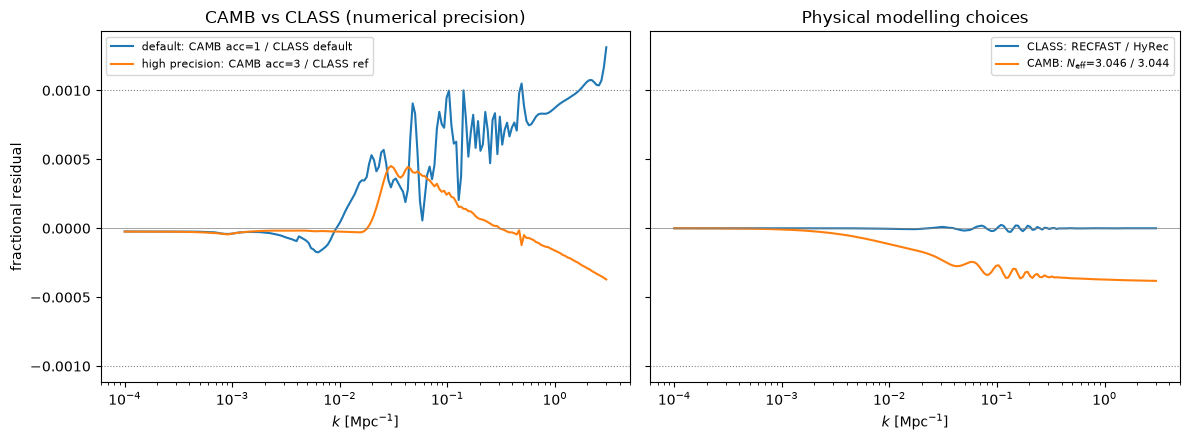

In [61]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

# Precision settings
ax1.semilogx(k_grid, r_default, label='default: CAMB acc=1 / CLASS default')
ax1.semilogx(k_grid, r_hi, label='high precision: CAMB acc=3 / CLASS ref')
ax1.set_title('CAMB vs CLASS (numerical precision)')
ax1.set_ylabel(r'fractional residual')

# Physical models for neutrinos and recomb. 
ax2.semilogx(k_grid, r_recomb, label='CLASS: RECFAST / HyRec')
ax2.semilogx(k_grid, r_neff, label=r'CAMB: $N_\mathrm{eff}$=3.046 / 3.044')
ax2.set_title('Physical modelling choices')

for ax in (ax1, ax2):
    ax.axhline(0, color='gray', lw=0.5)
    for s in (1e-3, -1e-3):
        ax.axhline(s, color='gray', ls=':', lw=0.8) 
    ax.set_xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$')
    ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(OUT / 'c_camb_vs_class.png', dpi=150)
plt.show()

In [62]:
#Values of the plot

comparisons = {
    'CAMB/CLASS, default precision':  r_default,
    'CAMB/CLASS, high precision':     r_hi,
    'CLASS RECFAST / HyRec':          r_recomb,
    'CAMB Neff 3.046 / 3.044':        r_neff,
}
for name, r in comparisons.items():
    print(f'{name:35s} max|diff| = {np.abs(r).max():.2e}')


CAMB/CLASS, default precision       max|diff| = 1.31e-03
CAMB/CLASS, high precision          max|diff| = 4.51e-04
CLASS RECFAST / HyRec               max|diff| = 2.64e-05
CAMB Neff 3.046 / 3.044             max|diff| = 3.82e-04


Note that the difference decreases as we the increase precision of the codes. 